# Figure 2: Fashion-MNIST distillation for a reservoir-type ONN

The measured data in Figures 2b, 2e and 2f are reconstructed by `Exp_an.ipynb`
from the supplied camera recordings.


## Run configuration



In [ ]:

import torch

SAVE_DETAILS = False  # Optional per-run diagnostics; keep inputs needed by SI.

SEARCH_LAMBDA = False    # True: repeat validation selection before simulation training.
DEVICE = 'cuda:0' if torch.cuda.is_available() else 'cpu'        # Choose an available CUDA device, or 'cpu'.


## Dataset and shared simulation parameters


In [2]:
from pathlib import Path
from utils.datasets import flat_result_path, flat_result_directory
from dataclasses import replace
import json
import numpy as np
import pandas as pd
torch.set_num_threads(4)
import torch.nn.functional as F
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display
from IPython import get_ipython
from utils.datasets import load_fmnist, load_npz, save_npz, save_distillation, random_coreset
from utils.reservoir_onn import set_seed, tm_ensemble
from utils.distillation import DistillationConfig, distill_coreset
from utils.evaluation import evaluate_coreset
from utils.hyperparameter_search import validation_split, search_lambda
from utils.experimental_analysis import sample_efficiency_table
from utils.plotting import COLORS, publication_style, muted_magma

ROOT = Path.cwd()
EXPERIMENTAL = ROOT / 'results/experimental'
RERUNS = ROOT / 'results/simulation/fmnist'
flat_result_directory(RERUNS).mkdir(parents=True, exist_ok=True)
IPC_VALUES = [1, 2, 5, 10, 20, 50, 100]
ABLATION_IPCS = [1, 5, 10]
TRAJECTORY_REPETITIONS = 5
SWEEP_REPETITIONS = 20
ABLATION_REPETITIONS = 20
TRAJECTORY_STEPS = 300
TRAJECTORY_EVAL_EVERY = 10
FULL_TM_COUNT = 5
BASE_SEED = 2025
OUTPUT_DIM = 1024
TM_COUNT = 50
publication_style()
get_ipython().run_line_magic('matplotlib', 'inline')

set_seed(BASE_SEED)
data = load_fmnist(ROOT / 'dataset', device=DEVICE, download=True)

base_config = DistillationConfig(steps=700, target_batch_size=1024,
                                 tms_per_step=4, lr_x=0.01, lr_y=0.01)

print('Train and evaluate from Fashion-MNIST.')


Train and evaluate from Fashion-MNIST.


## $\lambda$ selection


In [3]:
# Validation-selected ridge parameters; SEARCH_LAMBDA repeats the search.
lambda_selection = {'lambda_grid': [0.01, 0.1, 1.0, 10.0],
 'validation_size': 5000,
 'validation_split_seed': 424242,
 'methods': {'x_plus_y': {'1': 0.1,
                          '5': 0.01,
                          '10': 1.0,
                          '50': 1.0,
                          '2': 0.1,
                          '20': 1.0,
                          '100': 1.0},
             'only_x': {'1': 1.0, '5': 0.01, '10': 0.1, '50': 1.0, '2': 1.0, '20': 0.1, '100': 1.0},
             'only_y': {'1': 0.1, '5': 0.01, '10': 0.1},
             'random': {'1': 10.0,
                        '5': 1.0,
                        '10': 1.0,
                        '50': 1.0,
                        '2': 0.01,
                        '20': 1.0,
                        '100': 1.0}},
 'full_lambda': 0.01}
lambda_by_method = {method: {int(ipc): float(value) for ipc, value in table.items()}
                    for method, table in lambda_selection['methods'].items()}
full_lambda = float(lambda_selection['full_lambda'])
search_conditions = {'x_plus_y': IPC_VALUES, 'random': IPC_VALUES,
                     'only_x': ABLATION_IPCS, 'only_y': ABLATION_IPCS}
if SEARCH_LAMBDA:
    x_train_select, y_train_select, x_validation, y_validation = validation_split(
        data['x_train'], data['y_train'], lambda_selection['validation_size'],
        lambda_selection['validation_split_seed'])
    search_records = []
    for method, ipcs in search_conditions.items():
        for ipc in ipcs:
            candidate_config = replace(base_config, images_per_class=ipc)
            result = search_lambda(x_train_select, y_train_select, x_validation,
                                   y_validation, candidate_config, method=method,
                                   lambda_grid=lambda_selection['lambda_grid'],
                                   output_dim=OUTPUT_DIM, tm_count=TM_COUNT)
            lambda_by_method[method][ipc] = result['selected_lambda']
            for value, accuracy in zip(result['lambda_grid'], result['validation_accuracy']):
                search_records.append({'IPC': str(ipc), 'Method': method,
                                       'Lambda': value, 'Validation accuracy (%)': 100*accuracy})
    result = search_lambda(x_train_select, y_train_select, x_validation, y_validation,
                           base_config, method='full', lambda_grid=lambda_selection['lambda_grid'],
                           output_dim=OUTPUT_DIM, tm_count=TM_COUNT)
    full_lambda = result['selected_lambda']
    for value, accuracy in zip(result['lambda_grid'], result['validation_accuracy']):
        search_records.append({'IPC': 'Full', 'Method': 'full',
                               'Lambda': value, 'Validation accuracy (%)': 100*accuracy})
    search_table = pd.DataFrame(search_records)
    display(search_table)
    search_table.to_csv(flat_result_path(RERUNS / 'fmnist_lambda_search.csv'), index=False)
    lambda_selection['methods'] = {m: {str(k): v for k, v in t.items()}
                                   for m, t in lambda_by_method.items()}
    lambda_selection['full_lambda'] = full_lambda
    (flat_result_path(RERUNS / 'fmnist_lambda.json')).write_text(json.dumps(lambda_selection, indent=2))

print('Size sweep: selected ridge lambda')
display(pd.DataFrame({'Images + labels': [lambda_by_method['x_plus_y'][ipc] for ipc in IPC_VALUES],
                      'Random subset': [lambda_by_method['random'][ipc] for ipc in IPC_VALUES]},
                     index=IPC_VALUES).rename_axis('Images per class'))
print('Ablation: selected ridge lambda')
display(pd.DataFrame({label: [lambda_by_method[method][ipc] for ipc in ABLATION_IPCS]
                      for method, label in [('x_plus_y', 'Images + labels'), ('only_x', 'Images only'),
                                            ('only_y', 'Labels only'), ('random', 'Random subset')]},
                     index=ABLATION_IPCS).rename_axis('Images per class'))
print('Full-data lambda:', full_lambda)
print('Selection grid:', lambda_selection['lambda_grid'])


Size sweep: selected ridge lambda


,Images + labels,Random subset
Images per class,,
1,0.10,10.00
2,0.10,0.01
5,0.01,1.00
10,1.00,1.00
20,1.00,1.00
50,1.00,1.00
100,1.00,1.00


Ablation: selected ridge lambda


,Images + labels,Images only,Labels only,Random subset
Images per class,,,,
1,0.10,1.00,0.10,10.0
5,0.01,0.01,0.01,1.0
10,1.00,0.10,0.10,1.0


Full-data lambda: 0.01
Selection grid: [0.01, 0.1, 1.0, 10.0]


## Figure 2a: optimization dynamics



In [4]:
# Step 1: generate and evaluate the simulation results.
rows, final_scores = [], []
for repetition in range(TRAJECTORY_REPETITIONS):
    train_seeds = np.arange(1000+1000*repetition, 1000+1000*repetition+TM_COUNT)
    test_seeds = np.arange(9000+1000*repetition, 9000+1000*repetition+TM_COUNT)
    train_tms = tm_ensemble(data['input_dim'], OUTPUT_DIM, train_seeds, DEVICE)
    test_tms = tm_ensemble(data['input_dim'], OUTPUT_DIM, test_seeds, DEVICE)
    config = replace(base_config, images_per_class=1,
                     ridge_lambda=lambda_by_method['x_plus_y'][1], steps=TRAJECTORY_STEPS,
                     eval_every=TRAJECTORY_EVAL_EVERY, coreset_seed=BASE_SEED+repetition,
                     batch_seed=BASE_SEED+7000+repetition)
    result = distill_coreset(data['x_train'], data['y_train'], train_tms, config,
                            data['x_test'], data['y_test'], test_tms)
    evaluation = evaluate_coreset(result.x_coreset, result.y_coreset,
                                 data['x_test'], data['y_test'], test_tms, config.ridge_lambda)
    if SAVE_DETAILS:
        save_distillation(RERUNS / 'trajectory' / f'rep{repetition}.npz', result, config,
                          train_seeds, test_seeds, evaluation,
                          {'dataset': 'Fashion-MNIST', 'output_dim': OUTPUT_DIM, 'device': DEVICE})
    rows.append(result)
    final_scores.append(evaluation['accuracy_per_tm'])
    print(f'Repetition {repetition+1}/{TRAJECTORY_REPETITIONS}: '
          f'final test accuracy={100*evaluation["accuracy_mean"]:.3f}%', flush=True)
trajectory = {'loss': np.asarray([r.loss_history for r in rows]),
              'accuracy': np.asarray([r.accuracy_history for r in rows]),
              'accuracy_steps': rows[0].step_history,
              'final_accuracy_per_tm': np.asarray(final_scores),
              'mask': np.asarray([r.x_coreset.cpu().numpy() for r in rows]),
              'soft_labels': np.asarray([r.y_coreset.cpu().numpy() for r in rows]),
              'hard_labels': np.asarray([r.coreset_labels.cpu().numpy() for r in rows]),
              'source_indices': np.asarray([r.coreset_indices.cpu().numpy() for r in rows])}
save_npz(RERUNS / 'fmnist_trajectory.npz', trajectory,
         {'distillation': config, 'repetitions': TRAJECTORY_REPETITIONS})


Repetition 1/5: final test accuracy=79.120%


Repetition 2/5: final test accuracy=79.543%


Repetition 3/5: final test accuracy=78.731%


Repetition 4/5: final test accuracy=79.198%


Repetition 5/5: final test accuracy=78.989%


PosixPath('/home/laserthu/user_data/JJJ/release_validation/full_reproduction_20261022_002107/stage/results/simulation__fmnist__fmnist_trajectory.npz')

,Step,Mean test accuracy (%)
0,0,46.261
5,50,71.338
10,100,76.747
15,150,76.975
20,200,78.411
25,250,78.667
30,300,79.116


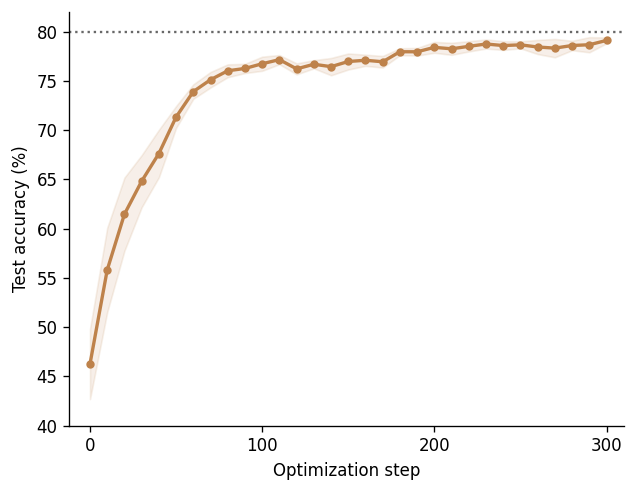

In [5]:
# Step 2: summarize and plot the results generated above.
steps = trajectory['accuracy_steps']
trajectory_mean = 100*trajectory['accuracy'].mean(axis=0)
trajectory_std = 100*trajectory['accuracy'].std(axis=0, ddof=1)
display(pd.DataFrame({'Step':steps, 'Mean test accuracy (%)':trajectory_mean}).iloc[::5].round(3))
fig, ax = plt.subplots(figsize=(5.4, 4.2))
ax.plot(steps, trajectory_mean, '-o', color=COLORS['trajectory'], lw=2, ms=4)
ax.fill_between(steps, trajectory_mean-trajectory_std, trajectory_mean+trajectory_std,
                 color=COLORS['trajectory'], alpha=0.12)
ax.axhline(80, color=COLORS['full'], ls=':', lw=1.4)
ax.set(xlabel='Optimization step', ylabel='Test accuracy (%)', xlim=(-12,310), ylim=(40,82))
ax.set_xticks([0,100,200,300])
fig.tight_layout()
plt.show()


## Figure 2b: simulation and measured coreset-size sweep


In [6]:
# Step 1: generate and evaluate the simulation results.
sweep_rows = {'x_plus_y': [], 'random': []}
for ipc in IPC_VALUES:
    distilled_accuracy, random_accuracy = [], []
    for repetition in range(SWEEP_REPETITIONS):
        train_seeds = np.arange(1000+1000*repetition, 1000+1000*repetition+TM_COUNT)
        test_seeds = np.arange(9000+1000*repetition, 9000+1000*repetition+TM_COUNT)
        train_tms = tm_ensemble(data['input_dim'], OUTPUT_DIM, train_seeds, DEVICE)
        test_tms = tm_ensemble(data['input_dim'], OUTPUT_DIM, test_seeds, DEVICE)
        config = replace(base_config, images_per_class=ipc,
                         ridge_lambda=lambda_by_method['x_plus_y'][ipc],
                         coreset_seed=BASE_SEED+repetition, batch_seed=BASE_SEED+7000+repetition)
        distilled = distill_coreset(data['x_train'], data['y_train'], train_tms, config)
        evaluation = evaluate_coreset(distilled.x_coreset, distilled.y_coreset,
                                     data['x_test'], data['y_test'], test_tms, config.ridge_lambda)
        distilled_accuracy.append(evaluation['accuracy_mean'])
        if (ipc in [1, 2, 5] and repetition < 20) or SAVE_DETAILS:
            save_distillation(RERUNS / 'sweep' / f'ipc{ipc}_rep{repetition}.npz', distilled,
                              config, train_seeds, test_seeds, evaluation,
                              {'dataset': 'Fashion-MNIST', 'output_dim': OUTPUT_DIM, 'device': DEVICE})
        xr, yr, hard, indices = random_coreset(data['x_train'], data['y_train'], ipc,
                                             BASE_SEED+20000+repetition)
        random_evaluation = evaluate_coreset(xr, yr, data['x_test'], data['y_test'],
                                            test_tms, lambda_by_method['random'][ipc])
        random_accuracy.append(random_evaluation['accuracy_mean'])
        if SAVE_DETAILS:
            save_npz(RERUNS / 'sweep' / f'random_ipc{ipc}_rep{repetition}.npz',
                     {'images': xr, 'targets': yr, 'hard_labels': hard, 'source_indices': indices,
                      'test_tm_seeds': test_seeds, 'accuracy_per_tm': random_evaluation['accuracy_per_tm']},
                     {'ridge_lambda': lambda_by_method['random'][ipc],
                      'coreset_seed': BASE_SEED+20000+repetition, 'output_dim': OUTPUT_DIM})
    sweep_rows['x_plus_y'].append(distilled_accuracy)
    sweep_rows['random'].append(random_accuracy)
full_seeds = np.arange(BASE_SEED+30000, BASE_SEED+30000+FULL_TM_COUNT)
full_tms = tm_ensemble(data['input_dim'], OUTPUT_DIM, full_seeds, DEVICE)
full = evaluate_coreset(data['x_train'], F.one_hot(data['y_train'],10).float(),
                        data['x_test'], data['y_test'], full_tms, full_lambda)
simulation = {'ipc_values': np.asarray(IPC_VALUES), 'full_mean': np.asarray(full['accuracy_mean']),
              'full_std': np.asarray(full['accuracy_std']), 'full_accuracy': full['accuracy_per_tm'],
              'full_beta': np.asarray(full_lambda), 'full_tm_seeds': full_seeds}
for method, values in sweep_rows.items():
    values = np.asarray(values)
    simulation[f'{method}_accuracy'] = values
    simulation[f'{method}_mean'] = values.mean(axis=1)
    simulation[f'{method}_std'] = values.std(axis=1,ddof=1)
    simulation[f'{method}_beta'] = np.asarray([lambda_by_method[method][ipc] for ipc in IPC_VALUES])
save_npz(RERUNS / 'fmnist_sweep.npz', simulation,
         {'lambda_selection': lambda_selection, 'distillation': base_config,
          'repetitions': SWEEP_REPETITIONS, 'output_dim': OUTPUT_DIM})
experiment = load_npz(EXPERIMENTAL / 'fmnist_experiment.npz')


,Images per class,Coreset simulation (%),Random simulation (%),Coreset experiment (%),Random experiment (%)
0,1,79.47 ± 0.42,48.64 ± 6.18,79.68 ± 0.62,48.73 ± 5.94
1,2,81.45 ± 0.25,55.86 ± 3.93,80.83 ± 0.64,55.81 ± 2.98
2,5,82.76 ± 0.27,65.84 ± 1.60,82.30 ± 0.59,65.57 ± 2.14
3,10,83.28 ± 0.20,71.17 ± 1.27,82.82 ± 0.47,71.10 ± 1.22
4,20,83.76 ± 0.17,75.20 ± 0.94,83.45 ± 0.40,74.73 ± 1.09
5,50,84.22 ± 0.14,78.91 ± 0.43,83.88 ± 0.63,78.64 ± 0.70
6,100,84.53 ± 0.13,80.85 ± 0.28,84.32 ± 0.34,80.55 ± 0.46


Full-data simulation: 85.30 ± 0.29%


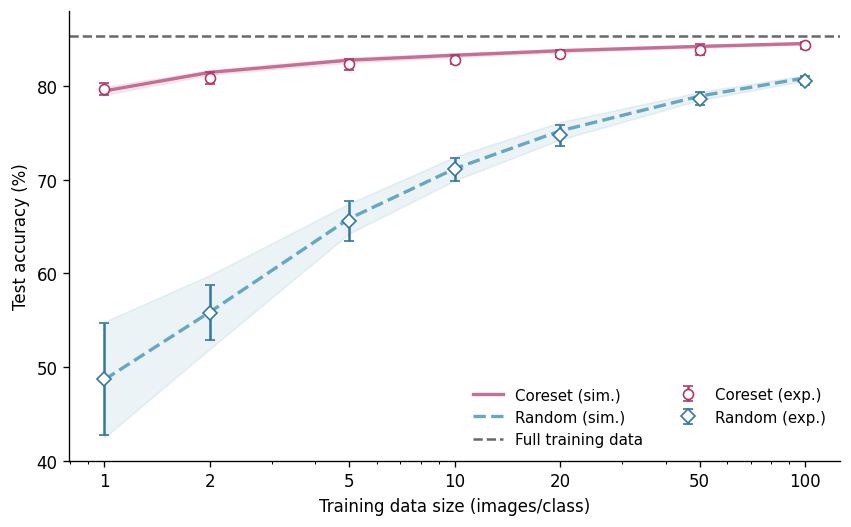

In [7]:
# Step 2: summarize and plot the results generated above.
ipc = simulation['ipc_values']

summary = pd.DataFrame({'Images per class':ipc})
for values,method,label in [(simulation,'x_plus_y','Coreset simulation'),
                            (simulation,'random','Random simulation'),
                            (experiment,'x_plus_y','Coreset experiment'),
                            (experiment,'random','Random experiment')]:
    indices = [int(np.flatnonzero(values['ipc_values']==value)[0]) for value in ipc]
    summary[f'{label} (%)'] = [f'{100*values[f"{method}_mean"][i]:.2f} ± {100*values[f"{method}_std"][i]:.2f}'
                              for i in indices]
display(summary)
print(f'Full-data simulation: {100*float(simulation["full_mean"]):.2f} ± '
      f'{100*float(simulation["full_std"]):.2f}%')
fig, ax = plt.subplots(figsize=(7.2, 4.5))
for method, color, exp_color, marker, linestyle, label in [
    ('x_plus_y',COLORS['coreset'],COLORS['coreset_exp'],'o','-','Coreset'),
    ('random',COLORS['random'],COLORS['random_exp'],'D','--','Random')]:
    mean, sd = 100*simulation[f'{method}_mean'], 100*simulation[f'{method}_std']
    ax.plot(ipc, mean, color=color, ls=linestyle, lw=2, label=f'{label} (sim.)')
    ax.fill_between(ipc, mean-sd, mean+sd, color=color, alpha=0.13)
    ax.errorbar(experiment['ipc_values'],100*experiment[f'{method}_mean'],yerr=100*experiment[f'{method}_std'],
                fmt=marker,color=exp_color,mfc='white',ms=6,capsize=3,label=f'{label} (exp.)')
ax.axhline(100*float(simulation['full_mean']),color=COLORS['full'],ls='--',label='Full training data')
ax.set(xscale='log',xlabel='Training data size (images/class)',ylabel='Test accuracy (%)',ylim=(40,88))
ax.set_xticks(ipc,labels=ipc.astype(str))
ax.legend(frameon=False,ncol=2,loc='lower right',fontsize=9)
fig.tight_layout()
plt.show()


## Figure 2c: Different optimization targets



In [8]:
# Step 1: generate and evaluate the simulation results.
ablation = {'bar_ipc_values': np.asarray(ABLATION_IPCS), 'class_names': data['class_names']}
for method in ['x_plus_y', 'only_x', 'only_y', 'random']:
    if method in ['x_plus_y', 'random'] and all(ipc in IPC_VALUES for ipc in ABLATION_IPCS):
        indices = [IPC_VALUES.index(ipc) for ipc in ABLATION_IPCS]
        values = simulation[f'{method}_accuracy'][indices]
    else:
        values = []
        for ipc in ABLATION_IPCS:
            repetition_scores = []
            for repetition in range(ABLATION_REPETITIONS):
                train_seeds = np.arange(1000+1000*repetition, 1000+1000*repetition+TM_COUNT)
                test_seeds = np.arange(9000+1000*repetition, 9000+1000*repetition+TM_COUNT)
                train_tms = tm_ensemble(data['input_dim'], OUTPUT_DIM, train_seeds, DEVICE)
                test_tms = tm_ensemble(data['input_dim'], OUTPUT_DIM, test_seeds, DEVICE)
                if method == 'random':
                    xs, ys, hard, indices = random_coreset(data['x_train'], data['y_train'], ipc,
                                                           BASE_SEED+20000+repetition)
                else:
                    config = replace(base_config, images_per_class=ipc,
                                     ridge_lambda=lambda_by_method[method][ipc],
                                     optimize_x=method!='only_y', optimize_y=method!='only_x',
                                     lr_x=0.005 if method=='only_x' else 0.01,
                                     lr_y=0.005 if method=='only_x' else 0.01,
                                     coreset_seed=BASE_SEED+repetition,
                                     batch_seed=BASE_SEED+7000+repetition)
                    distilled = distill_coreset(data['x_train'], data['y_train'], train_tms, config)
                    xs, ys = distilled.x_coreset, distilled.y_coreset
                evaluation = evaluate_coreset(xs, ys, data['x_test'], data['y_test'],
                                             test_tms, lambda_by_method[method][ipc])
                repetition_scores.append(evaluation['accuracy_mean'])
                if method != 'random':
                    if SAVE_DETAILS:
                        save_distillation(RERUNS / 'ablation' / f'{method}_ipc{ipc}_rep{repetition}.npz',
                                          distilled, config, train_seeds, test_seeds, evaluation,
                                          {'dataset': 'Fashion-MNIST', 'output_dim': OUTPUT_DIM, 'device': DEVICE})
                else:
                    if SAVE_DETAILS:
                        save_npz(RERUNS / 'ablation' / f'random_ipc{ipc}_rep{repetition}.npz',
                                 {'images': xs, 'targets': ys, 'source_indices': indices,
                                  'test_tm_seeds': test_seeds, 'accuracy_per_tm': evaluation['accuracy_per_tm']},
                                 {'ridge_lambda': lambda_by_method[method][ipc],
                                  'coreset_seed': BASE_SEED+20000+repetition, 'output_dim': OUTPUT_DIM})
            values.append(repetition_scores)
        values = np.asarray(values)
    ablation[f'bar_{method}_accuracy'] = values
    ablation[f'bar_{method}_mean'] = values.mean(axis=1)
    ablation[f'bar_{method}_std'] = values.std(axis=1,ddof=1)
save_npz(RERUNS / 'fmnist_ablation.npz', ablation,
         {'lambda_selection': lambda_selection, 'distillation': base_config,
          'repetitions': ABLATION_REPETITIONS, 'output_dim': OUTPUT_DIM})


PosixPath('/home/laserthu/user_data/JJJ/release_validation/full_reproduction_20261022_002107/stage/results/simulation__fmnist__fmnist_ablation.npz')

,Images + labels,Images only,Labels only,Random subset
Images per class,,,,
1,79.47 ± 0.42,78.67 ± 0.28,69.19 ± 1.00,48.64 ± 6.18
5,82.76 ± 0.27,82.21 ± 0.23,78.74 ± 0.26,65.84 ± 1.60
10,83.28 ± 0.20,82.96 ± 0.18,81.17 ± 0.20,71.17 ± 1.27


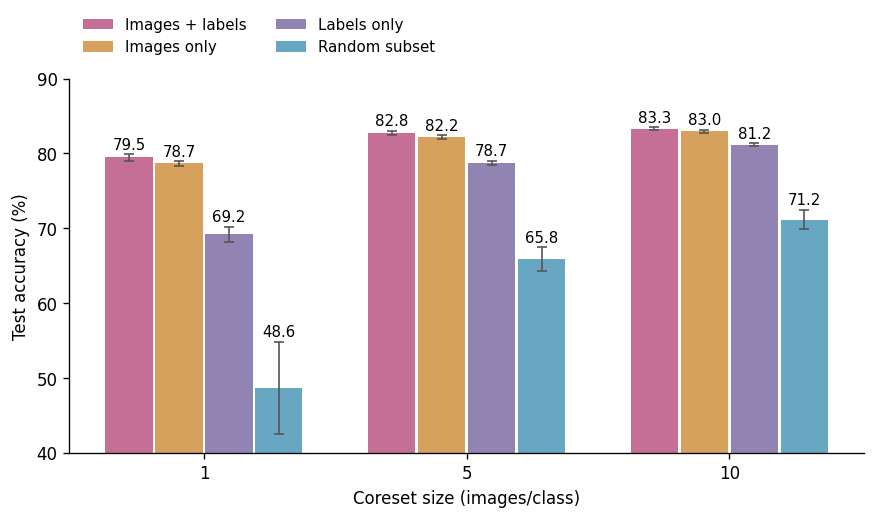

In [9]:
# Step 2: summarize and plot the results generated above.
methods=[('x_plus_y','Images + labels',COLORS['coreset']),
         ('only_x','Images only',COLORS['images']),
         ('only_y','Labels only',COLORS['labels']),
         ('random','Random subset',COLORS['random'])]

display(pd.DataFrame({label: [f'{100*mean:.2f} ± {100*sd:.2f}'
                              for mean,sd in zip(ablation[f'bar_{key}_mean'],ablation[f'bar_{key}_std'])]
                      for key,label,_ in methods},
                     index=ablation['bar_ipc_values']).rename_axis('Images per class'))
fig,ax=plt.subplots(figsize=(7.4,4.5))
positions=np.arange(len(ablation['bar_ipc_values']))
for offset,(key,label,color) in zip((np.arange(4)-1.5)*0.19,methods):
    mean,sd=100*ablation[f'bar_{key}_mean'],100*ablation[f'bar_{key}_std']
    bars=ax.bar(positions+offset,mean,width=0.18,color=color,yerr=sd,capsize=3,label=label,
                error_kw={'elinewidth':1,'ecolor':'#555555'})
    for bar,value,error in zip(bars,mean,sd):
        ax.text(bar.get_x()+bar.get_width()/2,value+error+0.7,f'{value:.1f}',ha='center',fontsize=9)
ax.set_xticks(positions,labels=ablation['bar_ipc_values'].astype(str))
ax.set(xlabel='Coreset size (images/class)',ylabel='Test accuracy (%)',ylim=(40,90))
ax.legend(frameon=False,ncol=2,loc='upper left',bbox_to_anchor=(0,1.2),fontsize=9)
fig.tight_layout()
plt.show()


## Figure 2d: original images, synthetic images and target vectors

One image per class, in class order. The saved visualization is a single
illustrative repetition and does not determine the quantitative sweep summary.
The images-only case retains one-hot targets; joint optimization uses free targets.


In [10]:
# Step 1: generate and evaluate the simulation results.
visualization = {'class_names': data['class_names']}
train_seeds = np.arange(1000,1000+TM_COUNT)
train_tms = tm_ensemble(data['input_dim'],OUTPUT_DIM,train_seeds,DEVICE)
for method,target in [('only_x','onlyx'),('x_plus_y','xy')]:
    config = replace(base_config,images_per_class=1,ridge_lambda=lambda_by_method[method][1],
                     optimize_x=True,optimize_y=method=='x_plus_y',
                     lr_x=0.005 if method=='only_x' else 0.01,
                     lr_y=0.005 if method=='only_x' else 0.01,
                     coreset_seed=BASE_SEED,batch_seed=BASE_SEED+7000)
    result = distill_coreset(data['x_train'],data['y_train'],train_tms,config)
    visualization[target] = result.x_coreset.cpu().numpy()
    visualization['orig'] = result.x_coreset_init.cpu().numpy()
    visualization['labels'] = result.coreset_labels.cpu().numpy()
    if method=='x_plus_y':
        visualization['softy'] = result.y_coreset.cpu().numpy()
    if SAVE_DETAILS:
        save_distillation(RERUNS / 'visualization' / f'{method}_ipc1.npz',result,config,train_seeds,
                          metadata={'dataset':'Fashion-MNIST','output_dim':OUTPUT_DIM,'device':DEVICE})
save_npz(RERUNS / 'fmnist_support_visualization.npz',visualization,lambda_selection)


PosixPath('/home/laserthu/user_data/JJJ/release_validation/full_reproduction_20261022_002107/stage/results/simulation__fmnist__fmnist_support_visualization.npz')

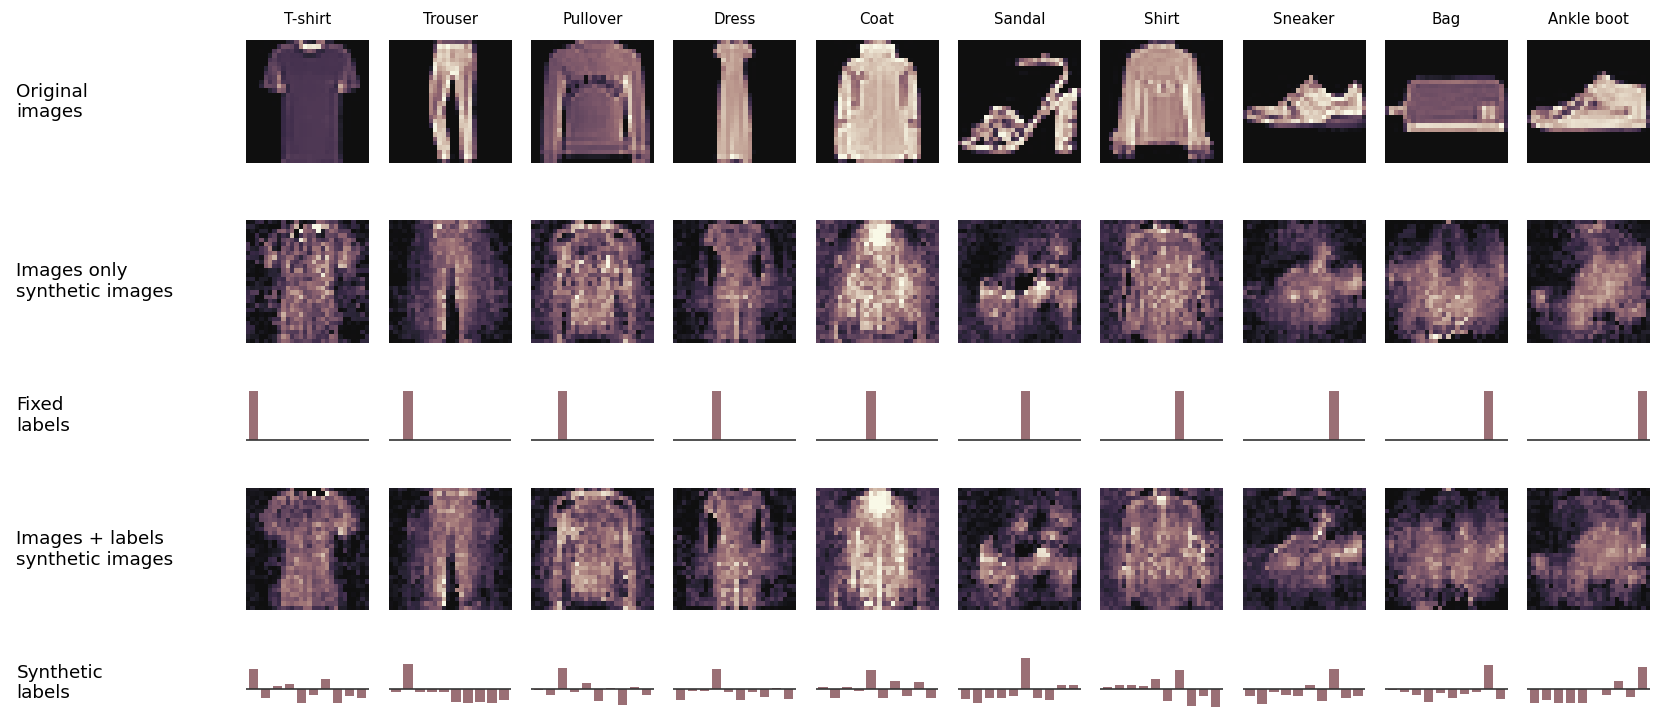

In [11]:
# Step 2: summarize and plot the results generated above.
order=np.argsort(visualization['labels'])
names=visualization['class_names'].astype(str)
fig=plt.figure(figsize=(14,6.4))
grid=fig.add_gridspec(5,11,width_ratios=[1.75]+[1]*10,height_ratios=[1,1,0.38,1,0.38],
                      left=0.02,right=0.995,bottom=0.04,top=0.93,hspace=0.28,wspace=0.15)
image_cmap=muted_magma()
labels_fixed=np.eye(10)[visualization['labels'][order].astype(int)]
row_values=[visualization['orig'][order],visualization['onlyx'][order],labels_fixed,
             visualization['xy'][order],visualization['softy'][order]]
row_names=['Original\nimages','Images only\nsynthetic images','Fixed\nlabels',
           'Images + labels\nsynthetic images','Synthetic\nlabels']
for row,values in enumerate(row_values):
    text_axis=fig.add_subplot(grid[row,0]);text_axis.set_axis_off()
    text_axis.text(0.02,0.5,row_names[row],va='center',fontsize=11)
    for col,value in enumerate(values):
        ax=fig.add_subplot(grid[row,col+1])
        if row in [0,1,3]:
            ax.imshow(value.reshape(28,28),cmap=image_cmap,vmin=0,vmax=1,interpolation='nearest')
            if row==0:ax.set_title(names[col].replace('T-shirt/top','T-shirt'),fontsize=9,pad=10)
        else:
            ax.bar(np.arange(10),value,width=0.78,color=image_cmap(0.62))
            ax.axhline(0,color='#333333',lw=1)
            ax.set_xlim(-0.6,9.6)
            if row==2:ax.set_ylim(-0.08,1.08)
            else:
                lo,hi=visualization['softy'].min(),visualization['softy'].max()
                pad=0.08*(hi-lo);ax.set_ylim(lo-pad,hi+pad)
        ax.set_axis_off()
plt.show()


## Figure 2e: measured IPC=1 confusion matrices



,Method,Test accuracy (%)
0,Synthetic coreset,80.14
1,Random subset,44.20


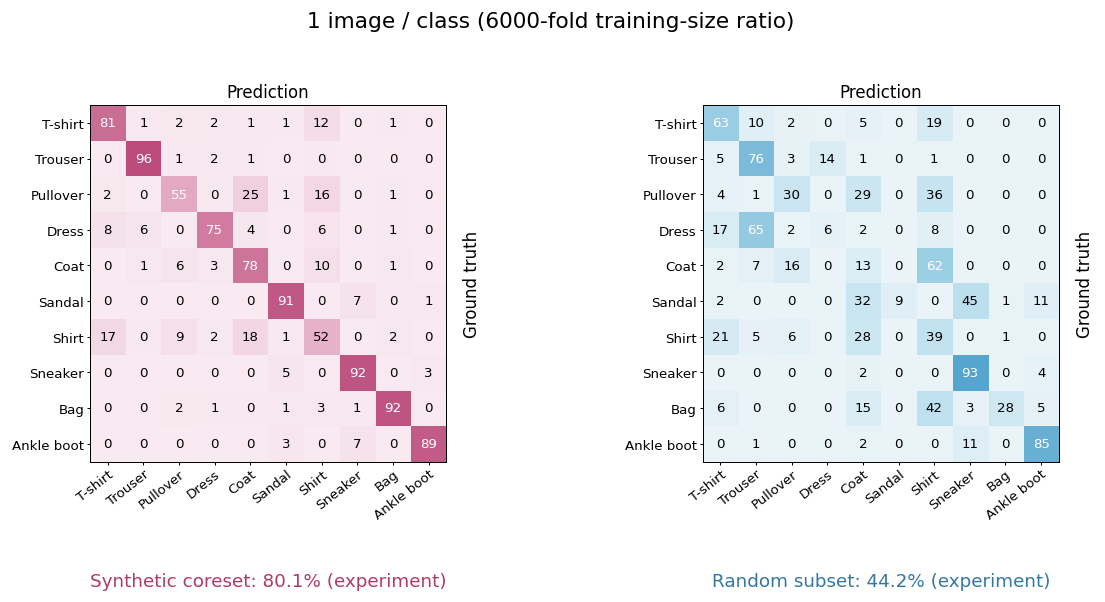

In [12]:
class_names=experiment['class_names'].astype(str)
class_names=np.where(class_names=='T-shirt/top','T-shirt',class_names)
assert str(experiment['selected_ipc1_source_file'])=='rep5_exp2.mat'
display(pd.DataFrame({'Method':['Synthetic coreset','Random subset'],
 'Test accuracy (%)':[100*float(experiment['selected_ipc1_x_plus_y_accuracy']),
                       100*float(experiment['selected_ipc1_random_accuracy'])]}).round(3))
fig,axes=plt.subplots(1,2,figsize=(10,5.4))
for ax,method,label,palette,color in [
    (axes[0],'x_plus_y','Synthetic coreset',['#F8EAF0','#E9B5CC','#B84375'],COLORS['coreset_exp']),
    (axes[1],'random','Random subset',['#EAF4F8','#B7DDED','#469DC9'],COLORS['random_exp'])]:
    values=experiment[f'selected_ipc1_{method}_percentages']
    cmap=LinearSegmentedColormap.from_list(method,palette)
    ax.imshow(values,cmap=cmap,vmin=0,vmax=100,interpolation='nearest',aspect='equal')
    for row,col in np.ndindex(values.shape):
        ax.text(col,row,f'{values[row,col]:.0f}',ha='center',va='center',fontsize=8,
                color='white' if values[row,col]>=55 else 'black')
    ax.set_xticks(np.arange(10),labels=class_names,rotation=38,ha='right',rotation_mode='anchor',fontsize=8)
    ax.set_yticks(np.arange(10),labels=class_names,fontsize=8)

    ax.tick_params(axis='both',which='both',length=2,width=0.6,pad=1.5,
                   top=False,bottom=True,left=True,right=False,colors='black')
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(0.6)
        spine.set_color('black')
    ax.grid(False)
    ax.set(xlim=(-0.5,9.5),ylim=(9.5,-0.5),xlabel='Prediction',ylabel='Ground truth')
    ax.xaxis.set_label_position('top')
    ax.xaxis.labelpad=5
    ax.yaxis.set_label_position('right')
    ax.yaxis.labelpad=10
    accuracy=100*float(experiment[f'selected_ipc1_{method}_accuracy'])
    ax.text(0.5,-0.31,f'{label}: {accuracy:.1f}% (experiment)',
            transform=ax.transAxes,ha='center',va='top',color=color,fontsize=11)
fig.suptitle('1 image / class (6000-fold training-size ratio)',fontsize=13,y=0.985)
fig.subplots_adjust(left=0.085,right=0.955,bottom=0.29,top=0.84,wspace=0.42)
plt.show()


## Figure 2f: experimental sample efficiency

Dots show arithmetic means across the nine acquisition-2 measurements. Gain labels are rounded to the nearest integer; calculations use unrounded means. Horizontal error bars span the minimum and maximum; the summary table reports sample standard deviations (ddof=1).


,Coreset IPC,Matched random IPC (mean),Matched random IPC (s.d.),Sample-efficiency gain (mean),Sample-efficiency gain (s.d.)
0,1,86.111,15.964,86.111,15.964
1,2,124.444,26.154,62.222,13.077
2,5,322.222,103.353,64.444,20.671
3,10,419.444,140.633,41.944,14.063


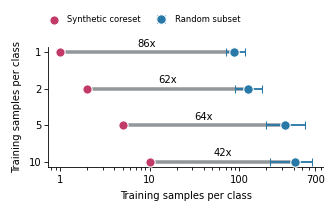

In [13]:
efficiency=load_npz(EXPERIMENTAL/'fmnist_sample_efficiency.npz')
display(sample_efficiency_table(efficiency).round(3))
core=efficiency['coreset_ipc'][:4]
matched_runs=efficiency['matched_random_ipc'][:,:4]
matched=matched_runs.mean(axis=0)
gain=matched/core
lower_bound=efficiency['aggregate_is_lower_bound'][:4]
position=np.arange(4)
# Match Figure 2f: 70 x 51 mm panel, 58.1 x 25.5 mm plotting area.
fig=plt.figure(figsize=(70/25.4,51/25.4))
ax=fig.add_axes([0.15,0.20,0.83,0.50])
for row,(small,large,value,bound) in enumerate(zip(core,matched,gain,lower_bound)):
    ax.plot([small,large],[row,row],color='#92979B',lw=2.1,zorder=1)
    ax.text(np.sqrt(small*large),row-0.15,f'{">" if bound else ""}{value:.0f}x',
            ha='center',fontsize=6)
ax.scatter(core,position,s=31,color='#C23B68',edgecolor='white',linewidth=0.65,
           zorder=3,label='Synthetic coreset')
ax.errorbar(matched,position,
            xerr=np.vstack([matched-matched_runs.min(axis=0),matched_runs.max(axis=0)-matched]),
            fmt='o',color='#2879A8',ms=5.7,elinewidth=1.1,capsize=2.4,
            markeredgecolor='white',markeredgewidth=0.65,label='Random subset',zorder=3)
ax.set(xscale='log',xlabel='Training samples per class',ylabel='Training samples per class',
        xlim=(0.75,850),ylim=(3.15,-0.15))
ax.set_xticks([1,10,100,700],labels=['1','10','100','700'])
ax.set_yticks(position,labels=core.astype(str))
ax.tick_params(axis='both',which='major',labelsize=6,length=2.3,width=0.5,pad=2)
ax.tick_params(axis='x',which='minor',length=2,width=0.5)
ax.xaxis.label.set_size(6)
ax.yaxis.label.set_size(6)
for spine in ax.spines.values():
    spine.set_linewidth(0.5)
ax.legend(frameon=False,loc='upper left',bbox_to_anchor=(0.13,0.845),
          bbox_transform=fig.transFigure,ncol=2,fontsize=5,columnspacing=1.5,
          handletextpad=0.6,borderaxespad=0)
plt.show()
